# Lab 28-01 · Scorecards, Evidence and the Value of a Test

Companion to [chapter 28-01](../../chapters/28-01-technology-evaluation-framework.md). Every part asks you to **predict first**, then run. All scores, probabilities and payoffs are the chapter's teaching assumptions; the spin distribution is read from the 2024 industry survey [R-645].

In [1]:
import sys, random
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, '.')
import dilmodel as dm
W, A, B, SA, SB = dm.WEIGHTS, dm.TARGET_A, dm.TARGET_B, dm.SIGMA_A, dm.SIGMA_B
print('A:', dm.weighted_score(W, A), ' B:', dm.weighted_score(W, B))
print('P(B ahead), analytic:', round(dm.p_second_ahead(W, A, SA, B, SB), 4),
      ' Monte Carlo:', round(dm.p_second_ahead_mc(W, A, SA, B, SB, n=50_000), 4))

A: 3.675  B: 3.6500000000000004


P(B ahead), analytic: 0.465  Monte Carlo: 0.4618


## Part 1 · What a deep-dive changes

Example 28-01.2: A leads B by 0.025 with a standard deviation of the difference of 0.285.

**Predict:** the probability that B is ahead if an architecture deep-dive revises A's architecture score from 4.5 to 4.0, with a standard deviation of 0.3.

In [2]:
def revised(score, sigma=0.3):
    a = list(A); a[0] = score
    s = list(SA); s[0] = sigma
    return a, s
a2, s2 = revised(4.0)
sd = (dm.score_variance(W, s2) + dm.score_variance(W, SB)) ** 0.5
print(f"A = {dm.weighted_score(W, a2):.3f}, sd of difference = {sd:.3f}, "
      f"P(B ahead) = {100*dm.p_second_ahead(W, a2, s2, B, SB):.1f}%")

A = 3.575, sd of difference = 0.249, P(B ahead) = 61.8%


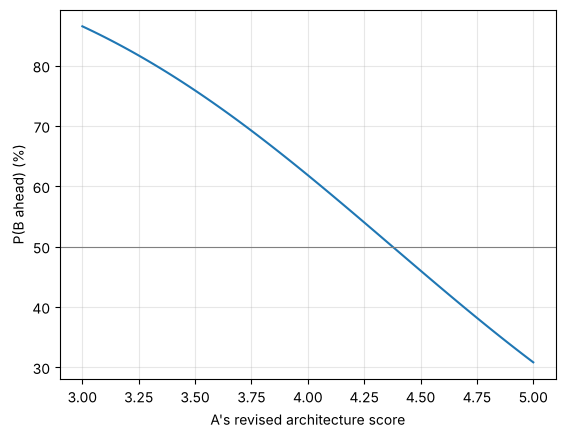

In [3]:
scores = np.linspace(3.0, 5.0, 81)
plt.plot(scores, [100 * dm.p_second_ahead(W, *revised(x), B, SB) for x in scores])
plt.axhline(50, color='grey', lw=0.8)
plt.xlabel("A's revised architecture score"); plt.ylabel('P(B ahead) (%)'); plt.grid(True, alpha=0.3); plt.show()

## Part 2 · One more signal

Example 28-01.3: prior 0.25 and likelihood ratios 3, 4 and 0.5 give a posterior of 2/3.

**Predict:** the posterior if a fourth, independent signal arrives with a likelihood ratio of 0.25.

In [4]:
print(f"three signals: {dm.posterior(0.25, [3, 4, 0.5]):.4f}")
print(f"four signals:  {dm.posterior(0.25, [3, 4, 0.5, 0.25]):.4f}")

three signals: 0.6667
four signals:  0.3333


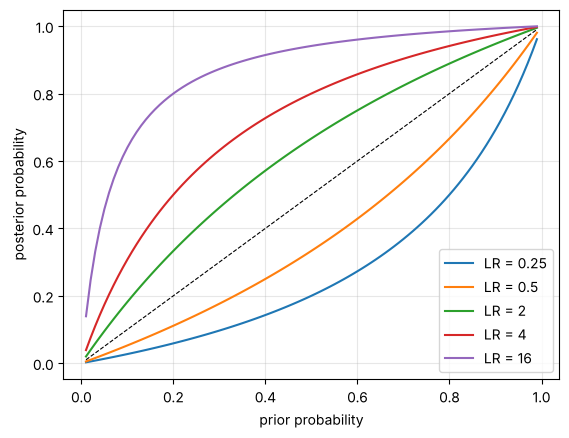

In [5]:
priors = np.linspace(0.01, 0.99, 99)
for lr in (0.25, 0.5, 2, 4, 16):
    plt.plot(priors, [dm.posterior(p, [lr]) for p in priors], label=f'LR = {lr}')
plt.plot(priors, priors, 'k--', lw=0.8)
plt.xlabel('prior probability'); plt.ylabel('posterior probability'); plt.legend(); plt.grid(True, alpha=0.3); plt.show()

## Part 3 · A three-spin plan

Example 28-01.4: 4 months and \$25 million per extra spin, against the 2024 distribution of spins before production.

**Predict:** the probability that a three-spin plan holds, and its expected delay and extra cost.

In [6]:
mean, p_ok, extra, delay, cost = dm.spin_stats(dm.SPINS_2024, 3, 4, 25)
print(f"P(plan holds) = {100*p_ok:.1f}%, extra spins = {extra:.3f}, delay = {delay:.2f} months, cost = ${cost:.1f}M")

P(plan holds) = 69.1%, extra spins = 0.495, delay = 1.98 months, cost = $12.4M


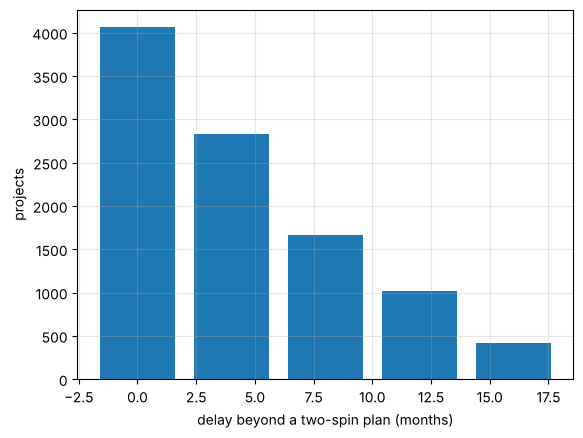

sample mean delay: 4.35 months


In [7]:
rng = random.Random(7)
ks, wts = zip(*dm.SPINS_2024.items())
draws = rng.choices(ks, weights=wts, k=10_000)
delays = [4 * max(0, k - 2) for k in draws]
plt.hist(delays, bins=[-2, 2, 6, 10, 14, 18], rwidth=0.8)
plt.xlabel('delay beyond a two-spin plan (months)'); plt.ylabel('projects'); plt.grid(True, alpha=0.3); plt.show()
print('sample mean delay:', round(np.mean(delays), 2), 'months')

## Part 4 · A less specific test

Example 28-01.6: gain \$500 million, loss \$200 million, prior 0.4, sensitivity 0.8, specificity 0.9 give an EVSI of \$68 million.

**Predict:** the EVSI if the specificity falls to 0.7.

In [8]:
for spec in (0.9, 0.7):
    v, pp, qp, ep, qf, ef = dm.evsi(0.4, 500, -200, 0.8, spec)
    print(f"specificity {spec}: P(pass) = {pp:.2f}, P(works|pass) = {qp:.2f}, "
          f"E[buy|pass] = {ep:.1f}, EVSI = {v:.1f}")

specificity 0.9: P(pass) = 0.38, P(works|pass) = 0.84, E[buy|pass] = 389.5, EVSI = 68.0
specificity 0.7: P(pass) = 0.50, P(works|pass) = 0.64, E[buy|pass] = 248.0, EVSI = 44.0


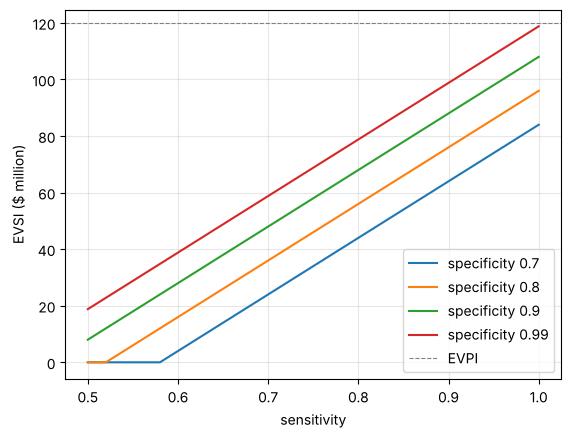

In [9]:
sens = np.linspace(0.5, 1.0, 51)
for spec in (0.7, 0.8, 0.9, 0.99):
    plt.plot(sens, [dm.evsi(0.4, 500, -200, a, spec)[0] for a in sens], label=f'specificity {spec}')
plt.axhline(dm.buy_or_pass(0.4, 500, -200)[1], color='grey', ls='--', lw=0.8, label='EVPI')
plt.xlabel('sensitivity'); plt.ylabel('EVSI ($ million)'); plt.legend(); plt.grid(True, alpha=0.3); plt.show()